### continuation de la carto en suivant l'exercice 3-2-3-bornes-métier-contre-outlier

avant toute chose je reprend la création de table de la carto 3-2-2 nettoyé

In [ ]:
import sys

# Affiche l'interpréteur réellement utilisé par ce code
print(sys.executable)

In [ ]:
import duckdb
import pandas as pd
import pyarrow as py
import matplotlib.pyplot as plt
from scipy import stats

con = duckdb.connect()

In [ ]:
con.sql("""
    CREATE TABLE products_nutrition AS
    SELECT
        t.code,
        t.product_name[1].text AS product_name,
        NULLIF(t.brands, '') AS brands,
        t.categories_tags,
        t.compared_to_category AS main_category,
        t.food_groups_tags[1] AS food_groups_tag_1,
        array_to_string(t.allergens_tags, ',') AS allergens,
        t.ingredients_text[1].text AS ingredients_text,
        t.nova_group,
        t.nutriscore_score,
        t.nutriscore_grade,
        t.serving_size,
        t.completeness,
        list_filter(t.nutriments, x -> x.name = 'energy-kcal')[1]."100g" AS energy_kcal_100g,
        COALESCE(
            list_filter(t.nutriments, x -> x.name = 'energy-kj')[1]."100g",
            list_filter(t.nutriments, x -> x.name = 'energy')[1]."100g"
        ) AS energy_kj_100g,
        list_filter(t.nutriments, x -> x.name = 'fat')[1]."100g" AS fat_100g,
        list_filter(t.nutriments, x -> x.name = 'saturated-fat')[1]."100g" AS saturated_fat_100g,
        list_filter(t.nutriments, x -> x.name = 'carbohydrates')[1]."100g" AS carbohydrates_100g,
        list_filter(t.nutriments, x -> x.name = 'sugars')[1]."100g" AS sugars_100g,
        list_filter(t.nutriments, x -> x.name = 'fiber')[1]."100g" AS fiber_100g,
        list_filter(t.nutriments, x -> x.name = 'proteins')[1]."100g" AS proteins_100g,
        list_filter(t.nutriments, x -> x.name = 'salt')[1]."100g" AS salt_100g,
        list_filter(t.nutriments, x -> x.name = 'sodium')[1]."100g" AS sodium_100g,
        list_filter(t.nutriments, x -> x.name = 'fruits-vegetables-legumes')[1]."100g" AS fruits_vegetables_legumes_100g
    FROM '../../data/food.parquet' AS t
""")

In [ ]:
con.sql("DROP TABLE products_nutrition")

In [ ]:
con.sql("DESCRIBE products_nutrition").show(max_rows=1000, max_width=200)

Dans un premier temps on va regarder quel rayon serais intéréssante a représenter pour afficher les outliers

In [19]:
def get_shelf_overview(con, min_count=1000):
    """Résume chaque rayon : effectif, valeurs manquantes et violations de règles métier."""
    return con.sql(f"""
        SELECT
            food_groups_tag_1 AS shelf,
            COUNT(*) AS products_count,
            -- Part de produits sans sucres renseignés (peu exploitable si élevée)
            ROUND(100 * AVG((sugars_100g IS NULL)::INT), 1) AS pct_missing_sugars,
            -- Part de produits sans énergie renseignée
            ROUND(100 * AVG((energy_kcal_100g IS NULL)::INT), 1) AS pct_missing_energy,
            -- Nombre de produits avec une énergie hors bornes 0-900
            SUM((energy_kcal_100g < 0 OR energy_kcal_100g > 900)::INT) AS energy_out_of_range,
            -- Nombre de produits avec des sucres hors bornes 0-100
            SUM((sugars_100g < 0 OR sugars_100g > 100)::INT) AS sugars_out_of_range,
            -- Nombre de produits avec sucres > glucides + 0,5
            SUM((sugars_100g > carbohydrates_100g + 0.5)::INT) AS sugars_above_carbs
        FROM products_nutrition
        GROUP BY food_groups_tag_1
        HAVING COUNT(*) >= {min_count}
        ORDER BY products_count DESC
    """).df()

print(get_shelf_overview(con).to_string(index=False))

                     shelf  products_count  pct_missing_sugars  pct_missing_energy  energy_out_of_range  sugars_out_of_range  sugars_above_carbs
                       NaN         3175085                40.4                34.6              17401.0               5825.0              1531.0
          en:sugary-snacks          294307                13.2                12.9                349.0                 91.0               258.0
         en:fish-meat-eggs          194405                16.9                13.7                189.0                  1.0               106.0
   en:cereals-and-potatoes          190151                10.7                 8.9                289.0                 12.0                54.0
en:milk-and-dairy-products          176374                11.7                 9.4                153.0                  7.0               299.0
              en:beverages          156498                16.8                13.2                330.0                491.0      

Pré-filtrage avec duckdb dans pandas des produits sur le top 9 des rayons ainsi que leurs nutriment clés composante au nutriscore :

In [ ]:
# Rayons retenus (alcoholic-beverages et baby-foods-and-milks exclus)
SHELVES = [
    "en:sugary-snacks", "en:fish-meat-eggs", "en:cereals-and-potatoes",
    "en:milk-and-dairy-products", "en:beverages", "en:fats-and-sauces",
    "en:fruits-and-vegetables", "en:composite-foods", "en:salty-snacks",
]


def load_shelves_data(con, shelves=SHELVES):
    """Charge dans pandas les produits des rayons retenus, avec uniquement les colonnes utiles."""
    return con.execute("""
        SELECT
            code,
            product_name,
            food_groups_tag_1,
            energy_kcal_100g,
            fat_100g,
            saturated_fat_100g,
            carbohydrates_100g,
            sugars_100g,
            fiber_100g,
            proteins_100g,
            salt_100g,
            sodium_100g
        FROM products_nutrition
        -- On ne garde que les lignes dont le rayon est dans la liste fournie
        WHERE list_contains(?, food_groups_tag_1)
    """, [shelves]).df()


df = load_shelves_data(con)
print(df.shape)  # attendu : (1419448, 12)

(1419448, 12)


On devrais créer un masque booléen pour l'exercice mais les valeurs aberranttes ont déja été traité dans l'exercice précédent, de ce fait je vais plutot faire le calcul IQR, Z-score et Z-robuste par rayon et par nutriment

In [24]:

SHELVES = [
    "en:sugary-snacks", "en:fish-meat-eggs", "en:cereals-and-potatoes",
    "en:milk-and-dairy-products", "en:beverages", "en:fats-and-sauces",
    "en:fruits-and-vegetables", "en:composite-foods", "en:salty-snacks",
]
KEY_NUTRIENTS = [
    "energy_kcal_100g", "saturated_fat_100g", "sugars_100g",
    "fiber_100g", "proteins_100g", "salt_100g",
]


def statistical_outliers(s: pd.Series) -> pd.DataFrame:
    """Retourne trois colonnes booléennes (iqr, z, z_robust) et indique si la MAD est nulle."""
    # float64 pour éviter les écarts d'arrondi de float32
    s = s.astype("float64")

    # Les NA sont ignorés automatiquement par quantile, mean, std et median
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mad = stats.median_abs_deviation(s.dropna(), scale="normal")

    result = pd.DataFrame(index=s.index)
    # IQR : hors de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR]
    result["iqr"] = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    # Z-score : écart à la moyenne supérieur à 3 écarts-types
    result["z"] = ((s - s.mean()) / s.std()).abs() > 3
    # Z-score robuste : si MAD nulle, la division est impossible, on ne signale rien
    if mad == 0:
        result["z_robust"] = False
    else:
        result["z_robust"] = ((s - s.median()) / mad).abs() > 3.5

    # Un NA donne False : un produit sans valeur n'est jamais signalé
    result = result.fillna(False).astype(bool)
    result.attrs["mad_is_zero"] = bool(mad == 0)
    return result


def count_outliers(df: pd.DataFrame, shelves=SHELVES, nutrients=KEY_NUTRIENTS) -> pd.DataFrame:
    """Retourne le % de produits signalés : une ligne par rayon et nutriment, une colonne par méthode."""
    rows = []
    for shelf in shelves:
        sub = df[df["food_groups_tag_1"] == shelf]
        for nutrient in nutrients:
            values = sub[nutrient]
            outliers = statistical_outliers(values)
            valid = int(values.notna().sum())

            row = {"shelf": shelf, "nutrient": nutrient, "valid": valid}
            # Une colonne par méthode : % de produits signalés parmi les valeurs renseignées
            for method in ["iqr", "z", "z_robust"]:
                row[method] = round(100 * int(outliers[method].sum()) / valid, 2) if valid else None
            row["mad_is_zero"] = outliers.attrs["mad_is_zero"]
            rows.append(row)
    return pd.DataFrame(rows)


counts = count_outliers(df)
print(counts.shape)  # attendu : (54, 7)
print(counts[counts["nutrient"] == "sugars_100g"].to_string(index=False))

(54, 7)
                     shelf    nutrient  valid   iqr    z  z_robust  mad_is_zero
          en:sugary-snacks sugars_100g 255442  1.52 0.01      0.03        False
         en:fish-meat-eggs sugars_100g 161568  7.19 1.15      5.51        False
   en:cereals-and-potatoes sugars_100g 169889 13.70 2.28     13.35        False
en:milk-and-dairy-products sugars_100g 155738  2.82 0.55      5.74        False
              en:beverages sugars_100g 130281  7.86 2.77      7.24        False
        en:fats-and-sauces sugars_100g 109341 14.11 0.31     14.87        False
  en:fruits-and-vegetables sugars_100g  84229 15.31 0.99     16.35        False
        en:composite-foods sugars_100g  94801  7.74 2.10      6.61        False
           en:salty-snacks sugars_100g  66282  5.44 2.47      4.67        False


Exemple d'analyse de l'IQR : 

14.11% de IQR sur fat-and-sauces veut dire que 14.11% des produit de ces rayons ont des valeurs de sugars qui diffère de la normal (différent de la majorité du rayon, pas forcément faux ou aberrants)

Exemple d'analyse du Z :

un z "normal" est aux alentour de 0.3  
z bas (moins de 1%) : méfiance, soit propre, soit seuil gonflé.  
z élevé (plus de 2 a 3%) : distribution asymétrique, pas forcément des erreurs.

Z et IQR :

z très inférieur à iqr (fats-and-sauces : 0,31 contre 14,11) : signe que l’écart-type est gonflé, donc le Z-score rate des outliers.  
z proche de iqr : l’écart-type est peu gonflé.

Exemple d'analyse du Z-robust :

z-robust bas (1 a 2%) : z-robust est basé sur la mediane et le MAD quand il est bas, il veut vraiment dire que la majorité des produits est groupé autour du centre
z-robust haut (10% et plus) : comme pour le Z c'est le signe d'une distribution asymétrique

Relation par rapport aux autres indicateurs : 

Z-robust et IQR similaire : les deux méthodes robuste s'accordent, le résultat est solide ici pour céréal confirme qu'on a environ 13 a 14% de produit qui différent vraiment de la majorité  
Z-robust très supérieur a Z : le Z-score est faussé par des valeurs absurdes, ici c'est le cas pour fruit et légumes (16,35 vs 0.99)  
Z-robust différent de IQR : un des deux seuils est plus bas que l'autre, pas un défaut la distribution est faite différement


Attention aux colonnes avec beaucoup de 0 pour le z-robust, la MAD devient miniscule et celui ci ne pourrais plus rien dire, c'est le cas lorsque la colonne mad_is_zero passe a true

#### Représentation graphique intéréssante :

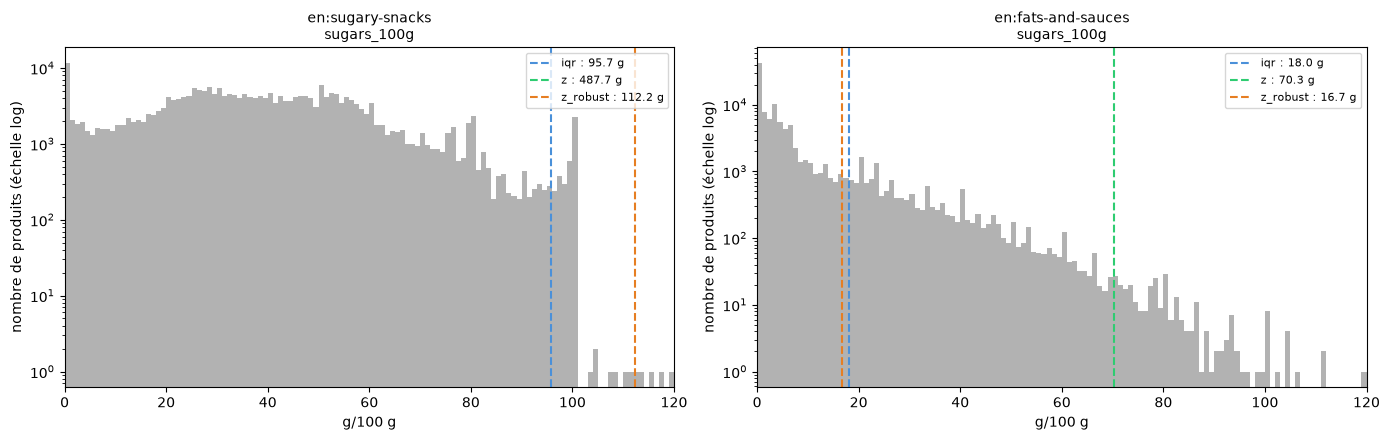

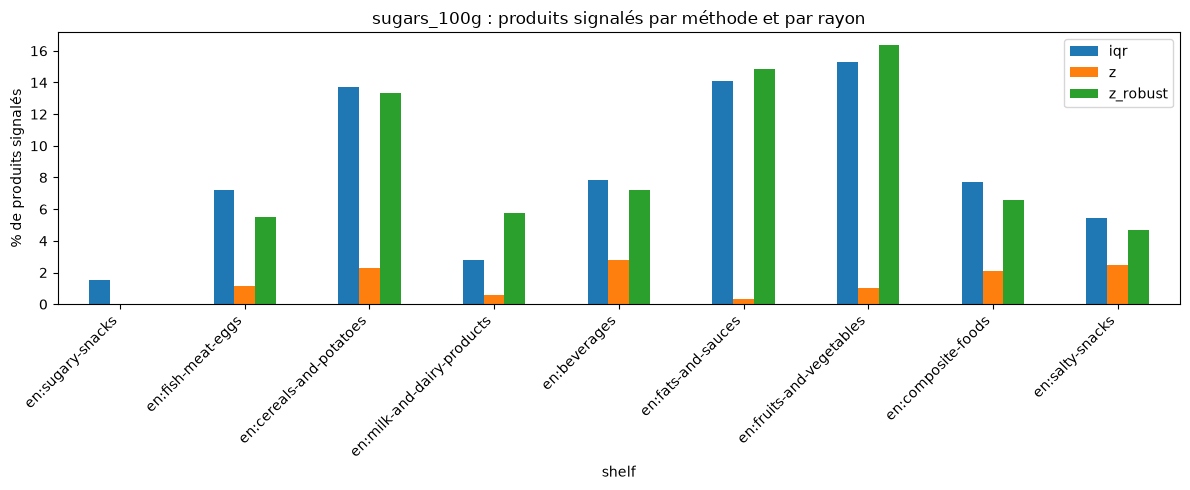

In [25]:
def plot_threshold_histogram(df, shelves, nutrient="sugars_100g", x_max=120, bins=120):
    """Trace la distribution d'un nutriment par rayon, avec le seuil haut de chaque méthode."""
    fig, axes = plt.subplots(1, len(shelves), figsize=(7 * len(shelves), 4.5))

    for ax, shelf in zip(axes, shelves):
        # Valeurs renseignées du rayon, en float64 pour les calculs
        s = df.loc[df["food_groups_tag_1"] == shelf, nutrient].dropna().astype("float64")

        # Seuils hauts des trois méthodes
        q1, q3 = s.quantile([0.25, 0.75])
        mad = stats.median_abs_deviation(s, scale="normal")
        thresholds = {
            "iqr": q3 + 1.5 * (q3 - q1),
            "z": s.mean() + 3 * s.std(),
            "z_robust": s.median() + 3.5 * mad,
        }

        # Histogramme limité à 0-x_max : les valeurs hors de cette plage ne sont pas dessinées
        ax.hist(s, bins=bins, range=(0, x_max), color="gray", alpha=0.6)

        # Une ligne verticale par méthode (la valeur du seuil figure dans la légende)
        for (method, value), color in zip(thresholds.items(), ["#4A90D9", "#2ECC71", "#E67E22"]):
            ax.axvline(value, color=color, linestyle="--", linewidth=1.5,
                       label=f"{method} : {value:.1f} g")

        # Bornes fixées après les lignes : un seuil au-delà de x_max reste dans la légende
        ax.set_xlim(0, x_max)
        # Échelle log sur les effectifs pour voir la queue de distribution
        ax.set_yscale("log")
        ax.set_title(f"{shelf}\n{nutrient}", fontsize=10)
        ax.set_xlabel("g/100 g")
        ax.set_ylabel("nombre de produits (échelle log)")
        ax.legend(fontsize=8)

    plt.tight_layout()
    return fig


fig = plot_threshold_histogram(df, ["en:sugary-snacks", "en:fats-and-sauces"])
plt.show()


def plot_flagged_bars(counts, nutrient="sugars_100g"):
    """Barres groupées : % de produits signalés par méthode, un groupe par rayon."""
    table = counts[counts["nutrient"] == nutrient].set_index("shelf")[["iqr", "z", "z_robust"]]
    ax = table.plot.bar(figsize=(12, 5))
    ax.set_ylabel("% de produits signalés")
    ax.set_title(f"{nutrient} : produits signalés par méthode et par rayon")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    return ax


plot_flagged_bars(counts)
plt.show()